# 01 - Exploratory data analysis: UCI Online Retail II
All tables come from the DuckDB model built by `make sql` (`sql/01..08`). Raw data is not committed - run `make data` first.

In [1]:
import os, json, duckdb, pandas as pd, numpy as np, matplotlib.pyplot as plt
os.chdir('..') if os.path.basename(os.getcwd()) == 'notebooks' else None
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 20)
con = duckdb.connect('data/processed/retail.duckdb', read_only=True)

## Data-quality profile and cleaning waterfall

In [2]:
con.execute('SELECT * FROM dq_report').df()

,check_name,n_rows
0,total_rows,1067371
1,exact_duplicate_rows,34335
2,cancellation_lines_invoice_C,19494
3,adjustment_lines_invoice_A,6
4,negative_quantity_lines,22950
5,negative_qty_not_cancelled,3457
6,zero_or_negative_price,6207
7,missing_customer_id,243007
8,missing_description,4382
9,non_product_stock_code,5834


In [3]:
con.execute('SELECT * FROM dq_cleaning_waterfall').df()

,step,n_rows
0,raw rows,1067371
1,clean lines (sales + cancellations),794154
2,clean sale lines,776570
3,clean cancellation lines,17584


## Grain and size of the clean model

In [4]:
con.execute('''SELECT 'fct_invoices' t, COUNT(*) n FROM fct_invoices UNION ALL
SELECT 'dim_customers', COUNT(*) FROM dim_customers UNION ALL SELECT 'fct_returns', COUNT(*) FROM fct_returns''').df()

,t,n
0,fct_invoices,36592
1,dim_customers,5852
2,fct_returns,7280


## Monthly revenue and active customers

,month,revenue,customers
20,2011-08-01,635514.38,933
21,2011-09-01,938752.63,1259
22,2011-10-01,1002326.56,1361
23,2011-11-01,1136534.00,1660
24,2011-12-01,343758.48,613


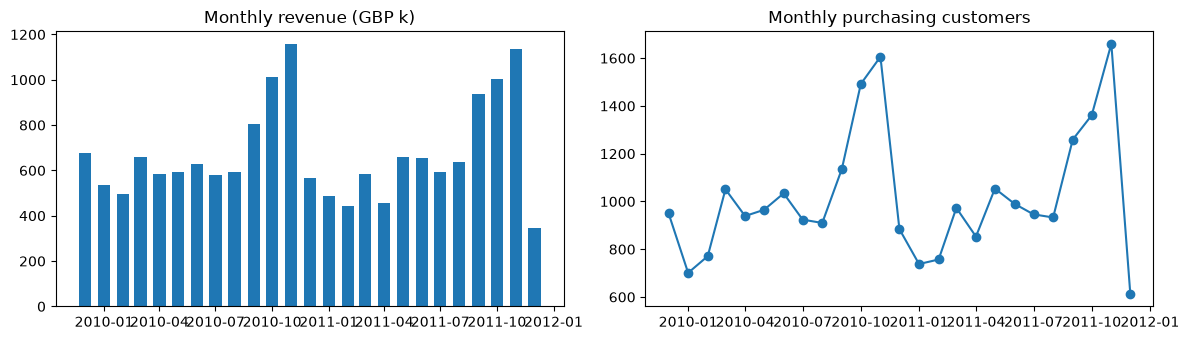

In [5]:
m = con.execute('''SELECT DATE_TRUNC('month', invoice_date) AS month, SUM(revenue) revenue,
       COUNT(DISTINCT customer_id) customers FROM fct_invoices GROUP BY 1 ORDER BY 1''').df()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].bar(m.month, m.revenue / 1e3, width=20); ax[0].set_title('Monthly revenue (GBP k)')
ax[1].plot(m.month, m.customers, 'o-'); ax[1].set_title('Monthly purchasing customers')
plt.tight_layout(); m.tail()

Strong Q4 seasonality (Sep-Nov) is visible - it matters for the churn proxy (see model notebook).

In [6]:
con.execute('SELECT * FROM monthly_active_customers ORDER BY month_end').df().tail(6)

,month_end,active_30d,active_60d,active_90d
18,2011-06-30,990,1627,1966
19,2011-07-31,925,1553,2019
20,2011-08-31,910,1480,1919
21,2011-09-30,1259,1755,2145
22,2011-10-31,1361,2113,2454
23,2011-11-30,1660,2405,2833


## Cohort retention

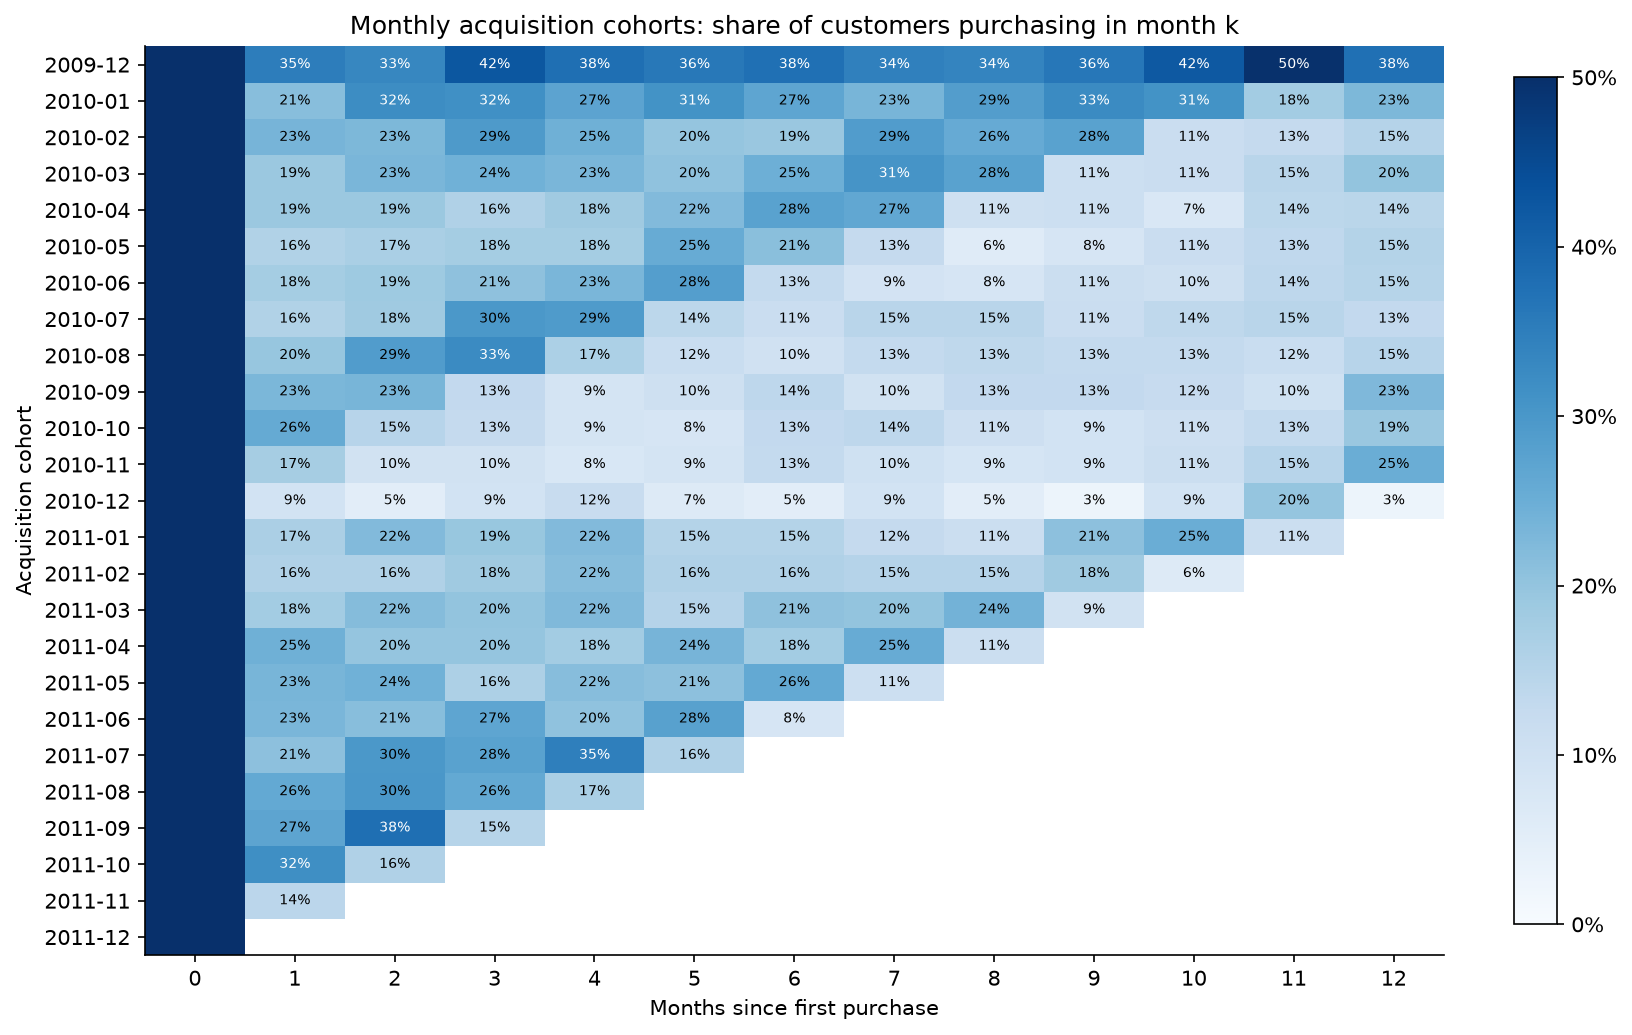

In [7]:
from IPython.display import Image; Image('docs/figures/cohort_retention_heatmap.png', width=800)

In [8]:
con.execute('''SELECT months_since_acquisition, AVG(retention_rate) avg_retention, COUNT(*) cohorts
FROM cohort_retention WHERE months_since_acquisition BETWEEN 1 AND 12 GROUP BY 1 ORDER BY 1''').df()

,months_since_acquisition,avg_retention,cohorts
0,1,0.209899,24
1,2,0.219378,23
2,3,0.217237,22
3,4,0.205876,21
4,5,0.188672,20
5,6,0.179182,19
6,7,0.177573,18
7,8,0.157325,17
8,9,0.153036,16
9,10,0.150762,15


## Customer concentration and RFM

In [9]:
c = con.execute('SELECT lifetime_revenue FROM dim_customers ORDER BY 1 DESC').df()
share = c.lifetime_revenue.cumsum() / c.lifetime_revenue.sum()
print(f"Top 10% of customers = {share.iloc[int(len(c)*0.1)-1]:.1%} of revenue; top 1% = {share.iloc[int(len(c)*0.01)-1]:.1%}")
con.execute('SELECT rfm_segment, COUNT(*) n, ROUND(AVG(monetary)) avg_monetary, ROUND(AVG(recency_days)) avg_recency '
            'FROM customer_rfm GROUP BY 1 ORDER BY 2 DESC').df()

Top 10% of customers = 63.4% of revenue; top 1% = 31.2%


,rfm_segment,n,avg_monetary,avg_recency
0,Hibernating,1525,351.0,457.0
1,Champions,1474,8044.0,20.0
2,Loyal,1221,2042.0,78.0
3,At risk,815,1958.0,367.0
4,New / Promising,440,389.0,28.0
5,Needs attention,377,431.0,108.0


## Countries

In [10]:
con.execute('SELECT home_country, COUNT(*) customers, ROUND(SUM(lifetime_revenue)) revenue FROM dim_customers GROUP BY 1 ORDER BY 2 DESC LIMIT 8').df()

,home_country,customers,revenue
0,United Kingdom,5334,14043106.0
1,Germany,107,384083.0
2,France,91,307923.0
3,Spain,36,97271.0
4,Belgium,27,60314.0
5,Portugal,23,46610.0
6,Netherlands,22,549773.0
7,Switzerland,21,91904.0
